# Iris Flower Classification
**CodeAlpha Data Science Internship — Task 1**

Tujuan: melatih model machine learning untuk mengklasifikasikan spesies bunga Iris (*setosa*, *versicolor*, *virginica*) berdasarkan ukuran sepal dan petal, lalu mengevaluasi performanya menggunakan data uji.

**Alur:** Import library → Load data → EDA → Visualisasi → Preprocessing → Training → Evaluasi → Cross-validation → Prediksi data baru → Kesimpulan

## 1. Import Library

In [22]:
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 2. Load Dataset
Pastikan file `Iris.csv` berada di folder yang sama dengan notebook ini.

In [24]:
df = pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Eksplorasi Data (EDA)

In [5]:
print("Ukuran data (baris, kolom):", df.shape)
print()
df.info()

Ukuran data (baris, kolom): (150, 6)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


In [ ]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nDistribusi kelas:")
print(df["Species"].value_counts())

In [6]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


**Catatan:** Dataset terdiri dari 150 sampel dengan 3 kelas yang seimbang (50 per kelas) dan tidak memiliki missing value. Kolom `Id` hanya nomor urut sehingga tidak dipakai sebagai fitur.

## 4. Visualisasi Data

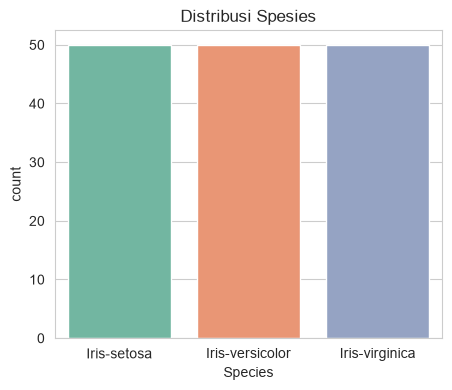

In [7]:
# Distribusi kelas
plt.figure(figsize=(5,4))
sns.countplot(data=df, x="Species", palette="Set2")
plt.title("Distribusi Spesies")
plt.show()

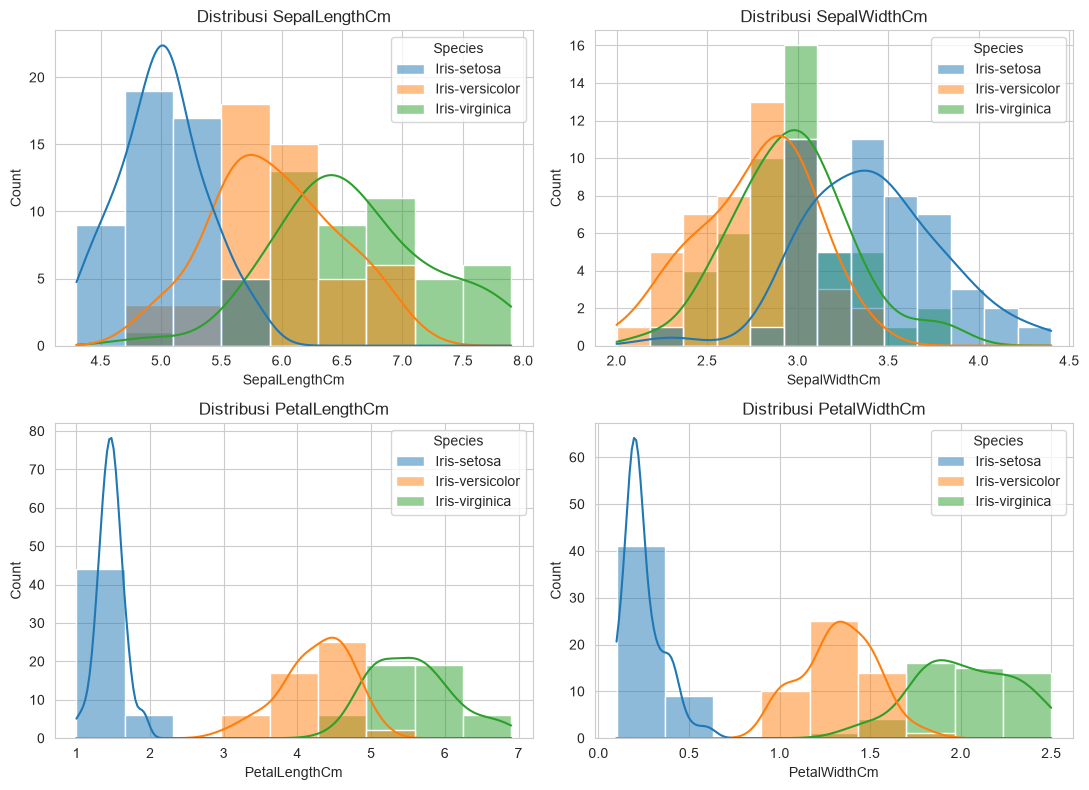

In [8]:
# Histogram tiap fitur per spesies
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Species", kde=True, ax=ax)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.show()

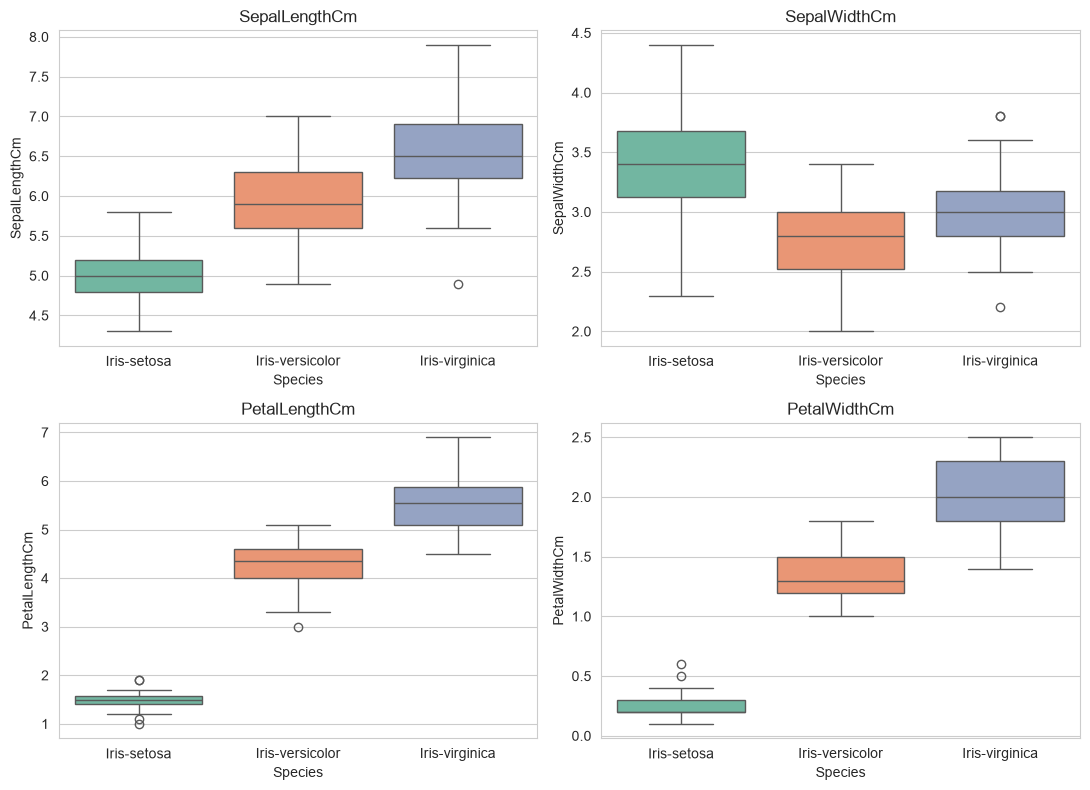

In [9]:
# Boxplot untuk melihat sebaran dan outlier
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Species", y=col, ax=ax, palette="Set2")
    ax.set_title(col)
plt.tight_layout()
plt.show()

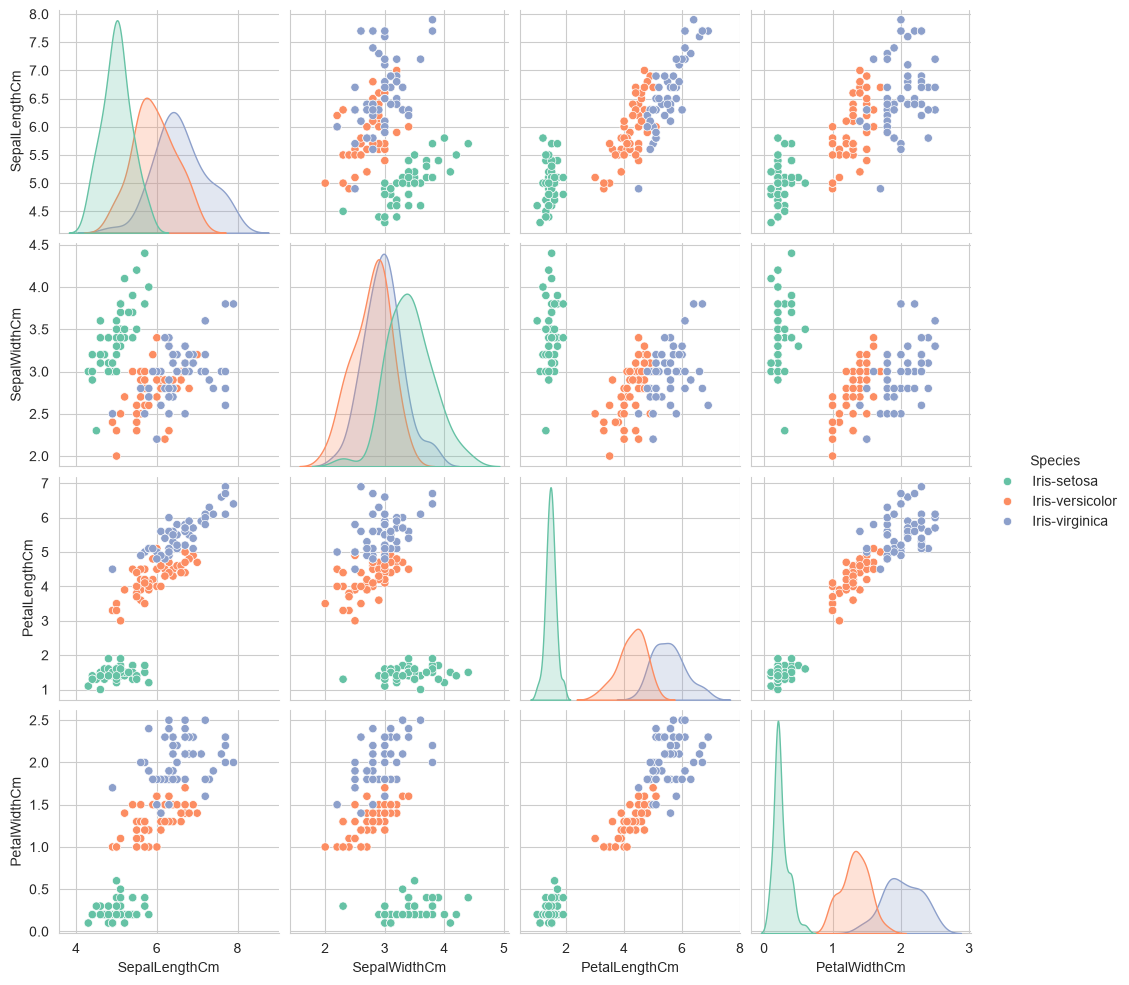

In [10]:
# Pairplot: hubungan antar fitur
sns.pairplot(df.drop(columns="Id"), hue="Species", palette="Set2")
plt.show()

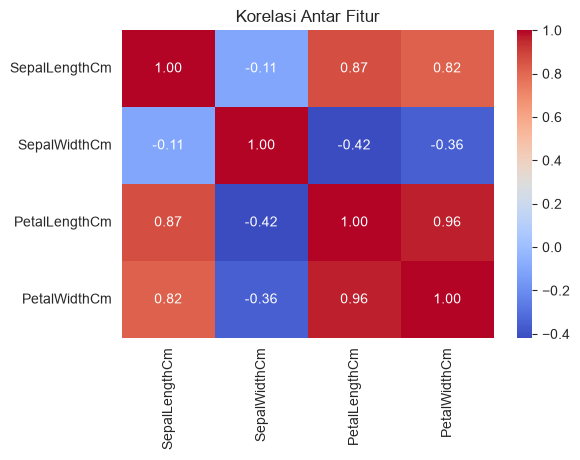

In [11]:
# Heatmap korelasi
plt.figure(figsize=(6,4))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi Antar Fitur")
plt.show()

**Temuan dari visualisasi:**
- *Iris-setosa* terpisah sangat jelas dari dua spesies lainnya, terutama pada ukuran petal.
- *Iris-versicolor* dan *Iris-virginica* sedikit tumpang tindih, sehingga kemungkinan di sinilah model paling sering salah.
- `PetalLengthCm` dan `PetalWidthCm` berkorelasi sangat kuat dan paling membedakan antar spesies.

## 5. Preprocessing
Langkah: pisahkan fitur dan target, bagi data latih/uji (80:20, stratified agar proporsi kelas terjaga), lalu standarisasi fitur.

In [12]:
X = df.drop(columns=["Id", "Species"])
y = df["Species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

# Scaler hanya di-fit pada data latih agar tidak terjadi data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Data latih: (120, 4) | Data uji: (30, 4)


## 6. Training & Perbandingan Beberapa Model

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    results[name] = accuracy_score(y_test, pred)

results_df = (pd.DataFrame.from_dict(results, orient="index", columns=["Accuracy"])
              .sort_values("Accuracy", ascending=False))
results_df

,Accuracy
SVM,0.966667
Logistic Regression,0.933333
KNN,0.933333
Decision Tree,0.900000
Random Forest,0.900000


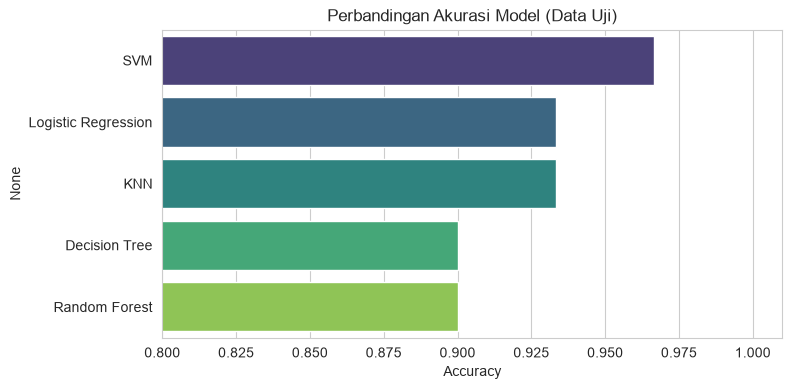

In [14]:
plt.figure(figsize=(8,4))
sns.barplot(x=results_df["Accuracy"], y=results_df.index, palette="viridis")
plt.xlim(0.8, 1.01)
plt.title("Perbandingan Akurasi Model (Data Uji)")
plt.show()

## 7. Cross-Validation
Dataset kecil (hanya 30 data uji), jadi satu kali split bisa menyesatkan. Cross-validation 5-fold memberi gambaran performa yang lebih stabil.

In [15]:
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_results[name] = (scores.mean(), scores.std())

cv_df = (pd.DataFrame(cv_results, index=["Mean Accuracy", "Std"]).T
         .sort_values("Mean Accuracy", ascending=False))
cv_df

,Mean Accuracy,Std
KNN,0.973333,0.024944
SVM,0.960000,0.038873
Decision Tree,0.953333,0.033993
Logistic Regression,0.953333,0.045216
Random Forest,0.946667,0.026667


## 8. Evaluasi Model Terbaik
Model terbaik dipilih otomatis berdasarkan rata-rata akurasi cross-validation.

In [16]:
best_name = cv_df.index[0]
best_model = models[best_name]
print("Model terbaik:", best_name)

y_pred = best_model.predict(X_test_scaled)
print("\nAccuracy pada data uji:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model terbaik: KNN

Accuracy pada data uji: 0.9333

Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



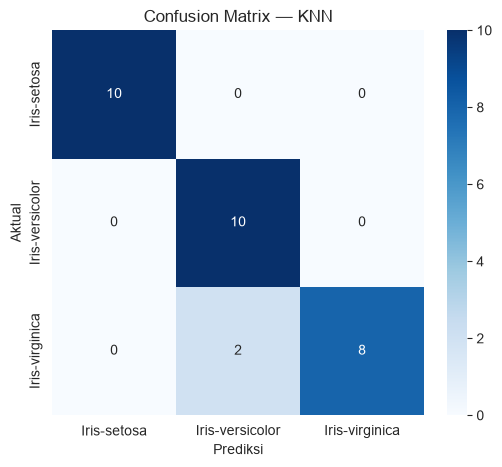

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

**Konsep evaluasi klasifikasi:**
- **Accuracy**: persentase prediksi yang benar dari seluruh data uji.
- **Precision**: dari semua data yang diprediksi sebagai kelas X, berapa persen yang benar-benar kelas X.
- **Recall**: dari semua data yang sebenarnya kelas X, berapa persen yang berhasil ditemukan model.
- **F1-score**: rata-rata harmonik precision dan recall; berguna untuk menyeimbangkan keduanya.
- **Confusion matrix**: tabel yang menunjukkan jumlah prediksi benar dan salah untuk setiap kelas, sehingga terlihat kelas mana yang sering tertukar.

## 9. Feature Importance (Random Forest)
Melihat fitur mana yang paling berpengaruh dalam membedakan spesies.

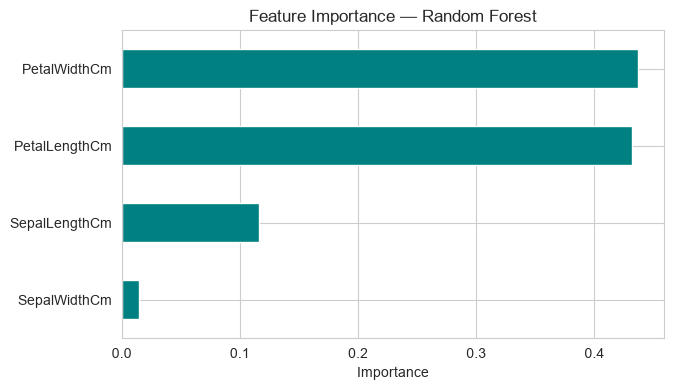

PetalWidthCm     0.437185
PetalLengthCm    0.431466
SepalLengthCm    0.116349
SepalWidthCm     0.015000
dtype: float64

In [18]:
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7,4))
importance.plot(kind="barh", color="teal")
plt.title("Feature Importance — Random Forest")
plt.xlabel("Importance")
plt.show()
importance.sort_values(ascending=False)

## 10. Prediksi Data Baru

In [19]:
new_data = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],   # mirip setosa
     [6.0, 2.9, 4.5, 1.5],   # mirip versicolor
     [6.9, 3.1, 5.4, 2.1]],  # mirip virginica
    columns=X.columns
)
predictions = best_model.predict(scaler.transform(new_data))
new_data["Prediksi"] = predictions
new_data

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Prediksi
0,5.1,3.5,1.4,0.2,Iris-setosa
1,6.0,2.9,4.5,1.5,Iris-versicolor
2,6.9,3.1,5.4,2.1,Iris-virginica


## 11. Menyimpan Model (opsional)

In [20]:
import joblib
joblib.dump(best_model, "iris_model.pkl")
joblib.dump(scaler, "iris_scaler.pkl")
print("Model dan scaler tersimpan.")

Model dan scaler tersimpan.


## 12. Kesimpulan
- Dataset Iris berisi 150 sampel, 4 fitur numerik, dan 3 kelas seimbang tanpa missing value.
- Beberapa model dibandingkan (Logistic Regression, KNN, SVM, Decision Tree, Random Forest); semuanya mencapai akurasi tinggi karena kelas pada dataset ini relatif mudah dipisahkan.
- Fitur **petal length** dan **petal width** adalah yang paling berpengaruh dalam membedakan spesies.
- *Iris-setosa* hampir selalu diprediksi dengan benar; kesalahan, jika ada, terjadi antara *versicolor* dan *virginica* karena distribusi ukurannya tumpang tindih.
- Cross-validation dipakai untuk memastikan hasil tidak hanya bergantung pada satu kali pembagian data.
